# 03 - Classification

Six classifiers plus a majority baseline, trained on applications filed 2000-2018 and tested on 2019-2022.

Steps: hyperparameter tuning with stratified 5-fold CV, choosing a decision threshold on a validation period,
final test evaluation, imbalance handling, preprocessing variants, feature importance and error analysis.

## Settings

In [1]:
TUNE_SAMPLE = 50_000      # training rows used for hyperparameter search
CV_FOLDS = 5
N_ITER = 8                # random search iterations per model
VAL_YEARS = (2017, 2018)  # validation period for choosing the threshold
RANDOM_STATE = 42

In [2]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import (precision_recall_curve, roc_curve, confusion_matrix,
                             average_precision_score, roc_auc_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from features import feature_groups
from modeling import make_preprocessor, make_models, PARAM_SPACES, best_f1_threshold, evaluate

FIG, OUT = ROOT / "figures", ROOT / "outputs"
OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=UserWarning)

## 1. Data and split

In [3]:
feats = pd.read_parquet(ROOT / "data" / "processed" / "features.parquet")
numeric, categorical, text = feature_groups(feats.columns)
X_cols = numeric + categorical + [text, "attorney_name"]

train = feats[feats["is_train"]].reset_index(drop=True)
test = feats[~feats["is_train"]].reset_index(drop=True)
y_train, y_test = train["failed"], test["failed"]

fit_part = train[train["filing_year"] < VAL_YEARS[0]]
val_part = train[train["filing_year"].between(*VAL_YEARS)]

pd.DataFrame({
    "rows": [len(train), len(fit_part), len(val_part), len(test)],
    "failure_rate": [y_train.mean(), fit_part["failed"].mean(), val_part["failed"].mean(), y_test.mean()],
}, index=["train 2000-2018", "  fit 2000-2016", "  validation 2017-2018", "test 2019-2022"]).round(4)

,rows,failure_rate
train 2000-2018,180442,0.1528
fit 2000-2016,159263,0.1541
validation 2017-2018,21179,0.1437
test 2019-2022,47047,0.1394


## 2. Preprocessing

Inside every pipeline (so it is fit on training folds only):
numeric columns are standardized, categorical columns one-hot encoded, and the English goods description goes
through TF-IDF (20,000 terms, English stop words removed) and TruncatedSVD to 50 components.
Trees don't need scaling, but it doesn't hurt them, so all models share the same preprocessing.

In [4]:
def make_pipeline(model, **pre_kwargs):
    return Pipeline([("pre", make_preprocessor(numeric, categorical, text, **pre_kwargs)), ("model", model)])

pre = make_preprocessor(numeric, categorical, text).fit(train.head(20000))
print("Model input size:", len(pre.get_feature_names_out()), "columns")

Model input size: 155 columns


## 3. Hyperparameter tuning

Random search with stratified 5-fold CV on a stratified sample of the training set, scored by PR-AUC
(average precision), which suits the 15% minority class better than accuracy.

In [5]:
tune, _ = train_test_split(train, train_size=TUNE_SAMPLE, stratify=y_train, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
models = make_models()

best_params, tuning_rows = {}, []
for name, space in PARAM_SPACES.items():
    start = time.time()
    n_combos = int(np.prod([len(v) for v in space.values()]))
    search = RandomizedSearchCV(make_pipeline(models[name]), space, n_iter=min(N_ITER, n_combos),
                                scoring="average_precision", cv=cv, random_state=RANDOM_STATE, n_jobs=1)
    search.fit(tune[X_cols], tune["failed"])
    best_params[name] = search.best_params_
    i = search.best_index_
    tuning_rows.append({"model": name,
                        "CV PR-AUC": f"{search.cv_results_['mean_test_score'][i]:.3f} ± {search.cv_results_['std_test_score'][i]:.3f}",
                        "best params": {k.replace('model__', ''): v for k, v in search.best_params_.items()},
                        "minutes": round((time.time() - start) / 60, 1)})
tuning = pd.DataFrame(tuning_rows)
tuning

,model,CV PR-AUC,best params,minutes
0,Logistic Regression,0.399 ± 0.008,{'C': 10},1.0
1,Decision Tree,0.424 ± 0.003,"{'min_samples_leaf': 100, 'max_depth': 20}",2.9
2,Random Forest,0.527 ± 0.006,"{'min_samples_leaf': 5, 'max_features': 0.3, '...",19.3
3,LightGBM,0.554 ± 0.008,"{'num_leaves': 127, 'n_estimators': 600, 'min_...",5.5
4,KNN,0.384 ± 0.004,"{'weights': 'distance', 'n_neighbors': 51}",1.9
5,MLP,0.439 ± 0.010,"{'learning_rate_init': 0.003, 'hidden_layer_si...",3.6


## 4. Final models

For each model: fit with the best parameters on 2000-2016, choose the threshold that maximizes F1 on 2017-2018,
then refit on all of 2000-2018 and evaluate once on the test set (2019-2022) with that threshold.

In [6]:
def fit_with_threshold(pipeline_factory):
    """Pick the F1 threshold on the validation years, then refit on the full training set."""
    pipe = pipeline_factory()
    pipe.fit(fit_part[X_cols], fit_part["failed"])
    threshold = best_f1_threshold(val_part["failed"], pipe.predict_proba(val_part[X_cols])[:, 1])
    pipe = pipeline_factory()
    pipe.fit(train[X_cols], y_train)
    return pipe, threshold

final, probas, results = {}, {}, []
for name, model in models.items():
    start = time.time()
    factory = lambda m=model, n=name: make_pipeline(clone(m)).set_params(**best_params.get(n, {}))
    if name.startswith("Baseline"):
        pipe, threshold = factory().fit(train[X_cols], y_train), 0.5
    else:
        pipe, threshold = fit_with_threshold(factory)
    final[name] = pipe
    probas[name] = pipe.predict_proba(test[X_cols])[:, 1]
    results.append({"model": name, **evaluate(y_test, probas[name], threshold),
                    "minutes": round((time.time() - start) / 60, 1)})

results = pd.DataFrame(results).set_index("model").round(3)
results.to_csv(OUT / "classification_test_results.csv")
results.sort_values("PR-AUC", ascending=False)

,ROC-AUC,PR-AUC,precision,recall,F1,threshold,minutes
model,,,,,,,
Random Forest,0.730,0.350,0.322,0.446,0.374,0.429,10.1
LightGBM,0.724,0.344,0.313,0.426,0.361,0.371,1.3
MLP,0.701,0.300,0.303,0.375,0.335,0.215,1.1
Logistic Regression,0.706,0.282,0.302,0.363,0.330,0.690,0.5
Decision Tree,0.677,0.282,0.277,0.403,0.328,0.635,0.8
KNN,0.652,0.263,0.236,0.419,0.301,0.190,1.2
Baseline (majority),0.500,0.139,0.000,0.000,0.000,0.500,0.2


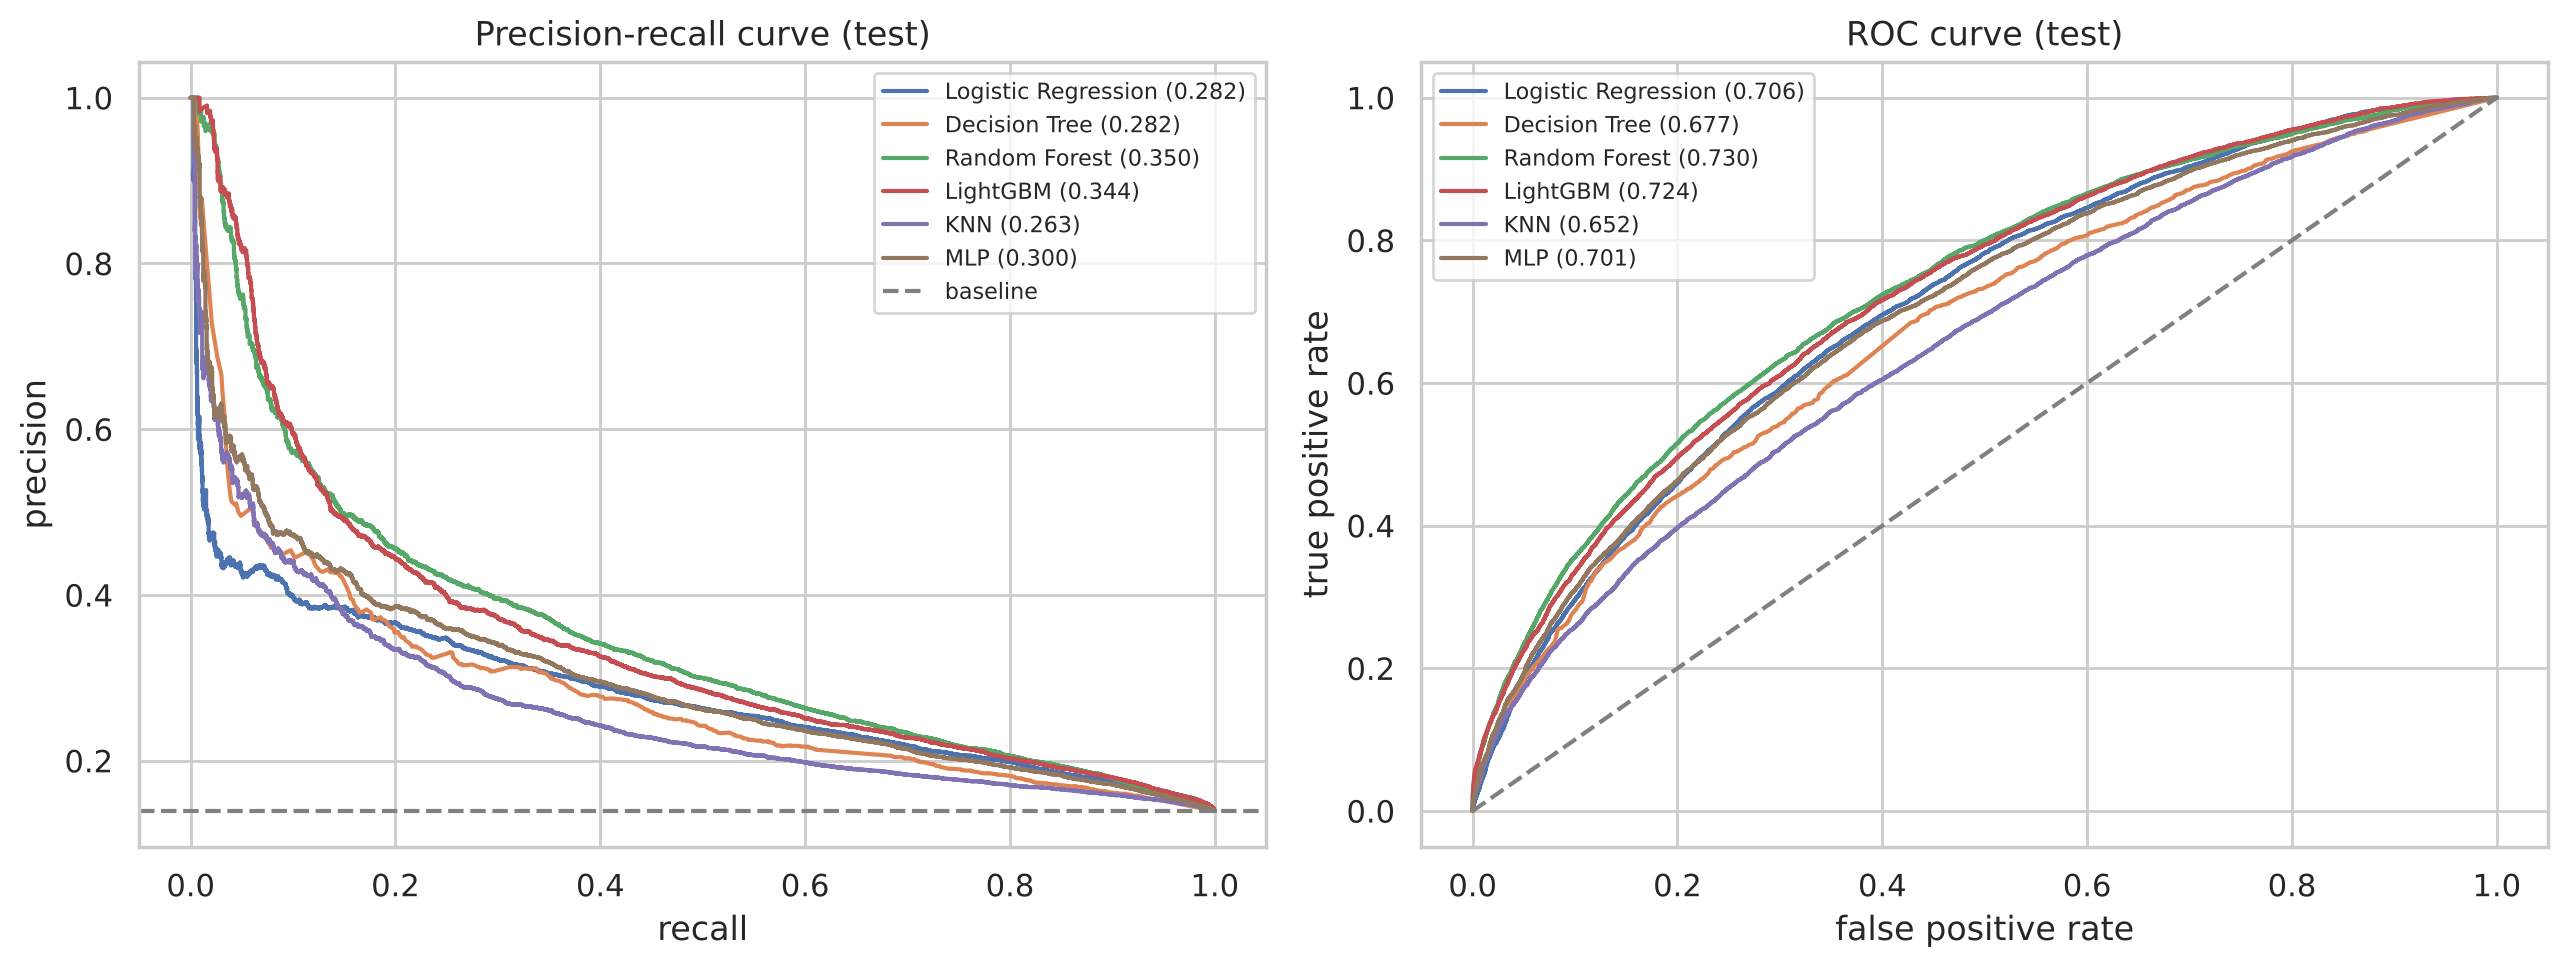

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probas.items():
    if name.startswith("Baseline"):
        continue
    prec, rec, _ = precision_recall_curve(y_test, p)
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(rec, prec, label=f"{name} ({results.loc[name, 'PR-AUC']:.3f})")
    axes[1].plot(fpr, tpr, label=f"{name} ({results.loc[name, 'ROC-AUC']:.3f})")
axes[0].axhline(y_test.mean(), color="grey", ls="--", label="baseline")
axes[0].set(xlabel="recall", ylabel="precision", title="Precision-recall curve (test)")
axes[1].plot([0, 1], [0, 1], color="grey", ls="--")
axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve (test)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "classification_curves.png", dpi=120)
plt.show()

**Results.** Random Forest and LightGBM are clearly the best (PR-AUC 0.35 and 0.34, ROC-AUC 0.73 and 0.72),
compared with 0.14 for the baseline. At the threshold chosen on 2017-2018, Random Forest catches 45% of the failures
with 32% precision. Logistic Regression, the Decision Tree and the MLP are in the middle, and KNN is the weakest.

The CV scores in section 3 (PR-AUC up to 0.55) are much higher than the test scores. The CV folds are random,
so they mix all years, while the test set is the future. Part of the signal doesn't hold for later years, and the
owner and attorney failure rates are frozen at 2018 for the test applications. This is the reason we evaluate on a time split.

## 5. Handling the imbalance

Compared on the two strongest model types: no adjustment, class weights, and SMOTE.
SMOTE runs inside the pipeline after preprocessing, so it only creates synthetic rows from the training data.
Each strategy is reported at the default 0.5 threshold and at the F1 threshold chosen on the validation years.

In [8]:
def strategy_pipeline(name, strategy):
    model = clone(models[name])
    params = {k.replace("model__", ""): v for k, v in best_params[name].items()}
    model.set_params(**params, class_weight="balanced" if strategy == "class weights" else None)
    if strategy == "SMOTE":
        return ImbPipeline([("pre", make_preprocessor(numeric, categorical, text)),
                            ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", model)])
    return Pipeline([("pre", make_preprocessor(numeric, categorical, text)), ("model", model)])

imbalance_rows = []
for name in ["LightGBM", "Logistic Regression"]:
    for strategy in ["none", "class weights", "SMOTE"]:
        pipe, threshold = fit_with_threshold(lambda: strategy_pipeline(name, strategy))
        p = pipe.predict_proba(test[X_cols])[:, 1]
        for label, thr in [("0.5", 0.5), ("tuned", threshold)]:
            m = evaluate(y_test, p, thr)
            imbalance_rows.append({"model": name, "strategy": strategy, "threshold": label,
                                   **{k: m[k] for k in ["ROC-AUC", "PR-AUC", "precision", "recall", "F1"]},
                                   "threshold value": round(thr, 3)})
imbalance = pd.DataFrame(imbalance_rows).round(3)
imbalance

,model,strategy,threshold,ROC-AUC,PR-AUC,precision,recall,F1,threshold value
0,LightGBM,none,0.5,0.728,0.351,0.573,0.116,0.193,0.500
1,LightGBM,none,tuned,0.728,0.351,0.345,0.366,0.355,0.194
2,LightGBM,class weights,0.5,0.724,0.344,0.377,0.292,0.329,0.500
3,LightGBM,class weights,tuned,0.724,0.344,0.313,0.426,0.361,0.371
4,LightGBM,SMOTE,0.5,0.723,0.346,0.575,0.124,0.205,0.500
5,LightGBM,SMOTE,tuned,0.723,0.346,0.351,0.337,0.344,0.224
6,Logistic Regression,none,0.5,0.702,0.282,0.426,0.079,0.134,0.500
7,Logistic Regression,none,tuned,0.702,0.282,0.282,0.410,0.334,0.254
8,Logistic Regression,class weights,0.5,0.706,0.282,0.223,0.679,0.336,0.500
9,Logistic Regression,class weights,tuned,0.706,0.282,0.302,0.363,0.330,0.690


**Imbalance.** The ranking quality (PR-AUC, ROC-AUC) is almost the same for all three strategies.
What changes is the threshold: LightGBM without any adjustment catches only 12% of the failures at 0.5, and 37% once the
threshold is tuned. After tuning, all strategies reach a similar F1 (0.33-0.36). SMOTE adds training time
without improving anything, so tuning the threshold is the simplest fix here.

## 6. Preprocessing variants

Threshold-free metrics on the test set for different input choices:
the full feature set, without the goods text, with one-hot columns for the 100 most frequent attorneys instead
of the attorney failure rate, and without any history features.

In [9]:
history = ["owner_fail_rate", "attorney_fail_rate", "owner_prior_filings", "attorney_prior_filings"]
variants = {
    "full": dict(num=numeric, text=text, onehot=False),
    "no goods text": dict(num=numeric, text=None, onehot=False),
    "attorney one-hot instead of rate": dict(num=[c for c in numeric if c != "attorney_fail_rate"], text=text, onehot=True),
    "no history features": dict(num=[c for c in numeric if c not in history], text=text, onehot=False),
}
variant_rows = []
for name in ["LightGBM", "Logistic Regression"]:
    for vname, v in variants.items():
        pipe = Pipeline([("pre", make_preprocessor(v["num"], categorical, v["text"], attorney_onehot=v["onehot"])),
                         ("model", clone(models[name]))]).set_params(**best_params[name])
        pipe.fit(train[X_cols], y_train)
        p = pipe.predict_proba(test[X_cols])[:, 1]
        variant_rows.append({"model": name, "variant": vname,
                             "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)})
variants_table = pd.DataFrame(variant_rows).round(3)
variants_table.pivot(index="variant", columns="model", values=["PR-AUC", "ROC-AUC"])

PR-AUC                      ROC-AUC  \
model                            LightGBM Logistic Regression LightGBM   
variant                                                                  
attorney one-hot instead of rate    0.343               0.285    0.721   
full                                0.344               0.282    0.724   
no goods text                       0.310               0.277    0.708   
no history features                 0.320               0.263    0.701   

                                                      
model                            Logistic Regression  
variant                                               
attorney one-hot instead of rate               0.708  
full                                           0.706  
no goods text                                  0.701  
no history features                            0.685

**Variants.** Removing the goods text hurts LightGBM the most (PR-AUC 0.344 -> 0.310), and removing the history
features hurts both models (0.344 -> 0.320, 0.282 -> 0.263). One-hot columns for the top 100 attorneys work about as well as
the single failure-rate column, so we keep the rate, which is one column instead of 100.

## 7. What drives the predictions

Permutation importance on the test set for the best model: each input column is shuffled and the drop in
PR-AUC is measured (the goods text is shuffled as one column). Groups of binary columns (Nice classes, Vienna codes) are shuffled together. Then SHAP values show the direction of the effects.

Best model: Random Forest


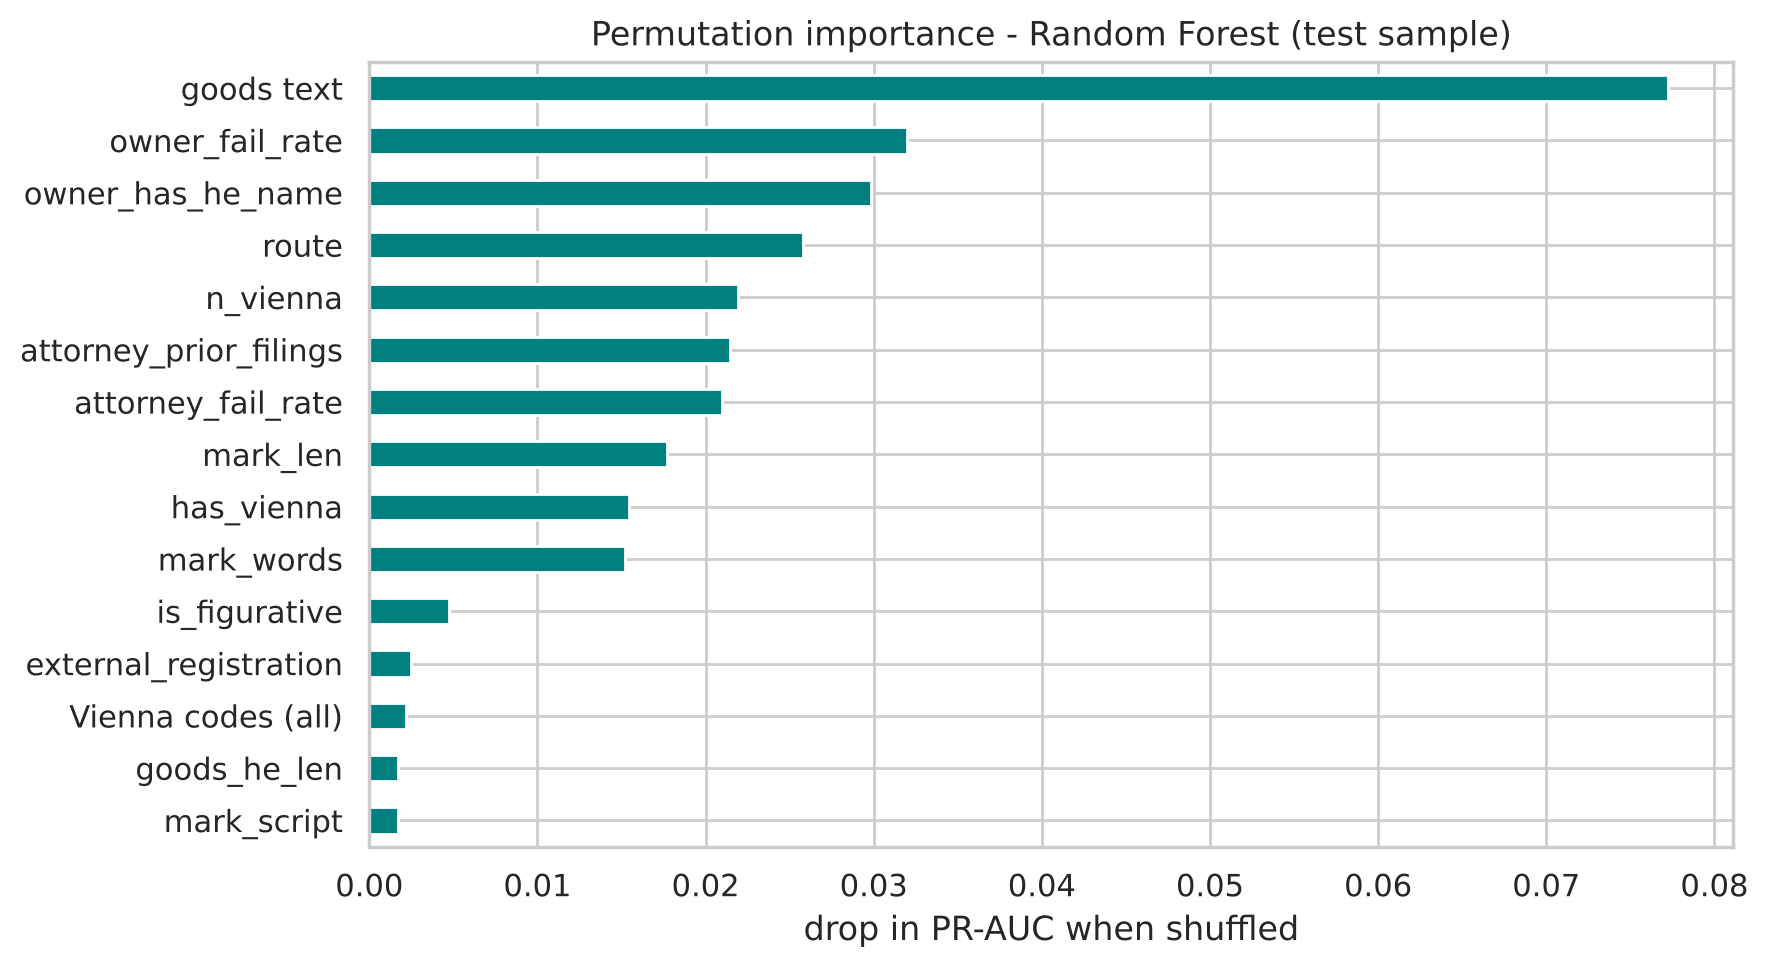

In [10]:
best_name = results.drop(index="Baseline (majority)")["PR-AUC"].idxmax()
best = final[best_name]
print("Best model:", best_name)

sample = test.sample(15_000, random_state=RANDOM_STATE).reset_index(drop=True)
groups = {c: [c] for c in numeric if not c.startswith(("nice_", "vienna_"))}
groups.update({c: [c] for c in categorical})
groups["goods text"] = [text]
groups["Nice classes (all)"] = [c for c in numeric if c.startswith("nice_")]
groups["Vienna codes (all)"] = [c for c in numeric if c.startswith("vienna_")]

rng = np.random.default_rng(RANDOM_STATE)
base_score = average_precision_score(sample["failed"], best.predict_proba(sample[X_cols])[:, 1])
drops = {}
for gname, cols in groups.items():
    scores = []
    for _ in range(3):
        shuffled = sample.copy()
        order = rng.permutation(len(sample))
        shuffled[cols] = sample[cols].to_numpy()[order]   # shuffle the group's columns together
        scores.append(average_precision_score(sample["failed"], best.predict_proba(shuffled[X_cols])[:, 1]))
    drops[gname] = base_score - np.mean(scores)
imp = pd.Series(drops)
imp = imp.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 5))
imp[::-1].plot.barh(ax=ax, color="teal")
ax.set_xlabel("drop in PR-AUC when shuffled")
ax.set_title(f"Permutation importance - {best_name} (test sample)")
plt.tight_layout()
plt.savefig(FIG / "permutation_importance.png", dpi=120)
plt.show()

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


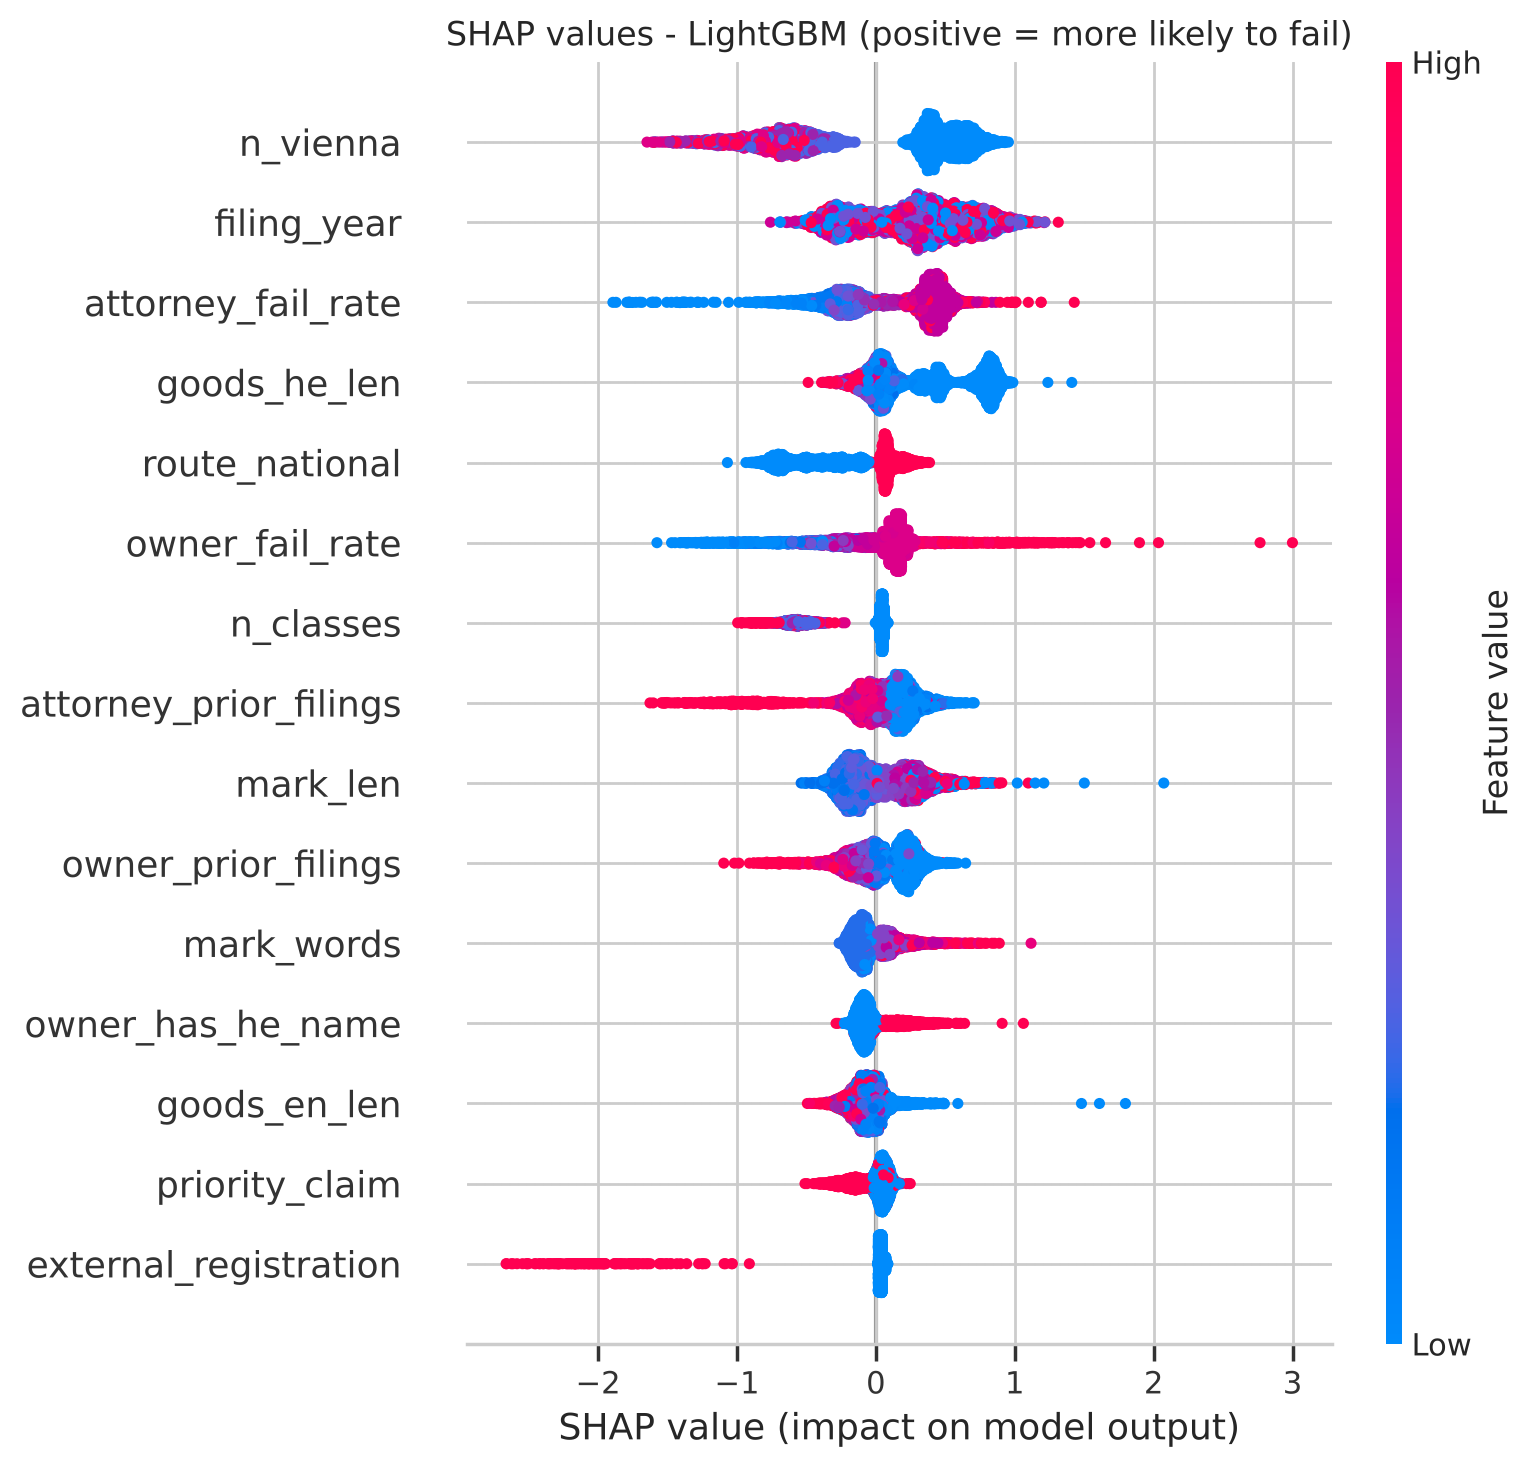

In [11]:
import shap

lgbm = final["LightGBM"]
X_shap = lgbm.named_steps["pre"].transform(sample.head(5000)[X_cols])
names = [n.split("__", 1)[1] for n in lgbm.named_steps["pre"].get_feature_names_out()]
explainer = shap.TreeExplainer(lgbm.named_steps["model"])
shap_values = explainer.shap_values(X_shap)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
shap.summary_plot(shap_values, X_shap, feature_names=names, max_display=15, show=False)
plt.title("SHAP values - LightGBM (positive = more likely to fail)")
plt.tight_layout()
plt.savefig(FIG / "shap_summary.png", dpi=120, bbox_inches="tight")
plt.show()

**Importance.** For Random Forest the goods text is the most important input, followed by the owner's past failure rate,
the Hebrew owner name, the filing route, the number of Vienna codes and the attorney features.
SHAP (LightGBM) shows the directions: more Vienna codes, more Nice classes, more prior filings by the attorney or owner,
a priority claim and an external registration all lower the risk; a high past failure rate, the national route and
a Hebrew owner name raise it.

`filing_year` ranks high in SHAP. Test years are outside the training range, so the trees treat all of them like 2018.
It may be better to drop the year in the next round and check if the test score changes.

## 8. Error analysis

In [12]:
threshold = results.loc[best_name, "threshold"]
pred = (probas[best_name] >= threshold).astype(int)
cm = confusion_matrix(y_test, pred)
print(f"{best_name}, threshold {threshold:.3f}")
pd.DataFrame(cm, index=["actual registered", "actual failed"], columns=["predicted registered", "predicted failed"])

Random Forest, threshold 0.429


,predicted registered,predicted failed
actual registered,34309,6180
actual failed,3625,2933


In [13]:
err = test.assign(pred=pred, proba=probas[best_name])

def group_metrics(col):
    rows = []
    for value, g in err.groupby(col):
        if len(g) < 300:
            continue
        tp = ((g["pred"] == 1) & (g["failed"] == 1)).sum()
        rows.append({col: value, "n": len(g), "failure_rate": g["failed"].mean(),
                     "precision": tp / max(g["pred"].sum(), 1), "recall": tp / max(g["failed"].sum(), 1),
                     "PR-AUC": average_precision_score(g["failed"], g["proba"]) if g["failed"].nunique() > 1 else np.nan})
    return pd.DataFrame(rows).set_index(col).round(3)

for col in ["filing_year", "route", "mark_script"]:
    display(group_metrics(col))

,n,failure_rate,precision,recall,PR-AUC
filing_year,,,,,
2019,11109,0.145,0.352,0.509,0.425
2020,11333,0.137,0.322,0.468,0.353
2021,12778,0.139,0.307,0.423,0.313
2022,11827,0.137,0.306,0.393,0.307


,n,failure_rate,precision,recall,PR-AUC
route,,,,,
base_for_international,1435,0.029,0.000,0.000,0.048
international,26173,0.123,0.320,0.323,0.297
national,19439,0.170,0.323,0.574,0.401


,n,failure_rate,precision,recall,PR-AUC
mark_script,,,,,
both,2269,0.278,0.356,0.830,0.529
hebrew,2343,0.195,0.369,0.777,0.509
latin,39692,0.132,0.308,0.383,0.313
none,2362,0.075,0.290,0.205,0.210
other,381,0.110,0.243,0.214,0.258


In [14]:
nice_cols = [c for c in err if c.startswith("nice_")]
rows = []
for c in nice_cols:
    g = err[err[c] == 1]
    if len(g) < 1000:
        continue
    tp = ((g["pred"] == 1) & (g["failed"] == 1)).sum()
    rows.append({"Nice class": int(c.split("_")[1]), "n": len(g), "failure_rate": g["failed"].mean(),
                 "recall": tp / max(g["failed"].sum(), 1), "PR-AUC": average_precision_score(g["failed"], g["proba"])})
by_class = pd.DataFrame(rows).set_index("Nice class").sort_values("PR-AUC").round(3)
pd.concat([by_class.head(5), by_class.tail(5)])

,n,failure_rate,recall,PR-AUC
Nice class,,,,
34,1183,0.129,0.366,0.203
28,1794,0.084,0.391,0.234
14,1139,0.115,0.328,0.237
12,1978,0.108,0.243,0.239
25,3427,0.132,0.412,0.257
38,1837,0.110,0.441,0.381
44,2147,0.122,0.479,0.394
29,1942,0.170,0.509,0.395
43,1855,0.165,0.614,0.442


**Errors.** Performance drops every year of the test period (PR-AUC 0.43 in 2019 down to 0.31 in 2022), which fits the
idea that the history features get older. National applications are predicted better than international ones (0.40 vs 0.30).
The "base for international" route almost never fails and the model flags none of them.
Hebrew marks are caught well (recall about 0.8). The weakest Nice classes are 34 (tobacco), 28 (toys), 14, 12 and 25 (clothing).

In [15]:
joblib.dump(best, OUT / f"best_model_{best_name.replace(' ', '_').lower()}.joblib", compress=3)
pd.Series(best_params).to_json(OUT / "best_params.json", indent=2)
print("saved")

saved
